# FlipFlop vs MOIA: Simulated Ridepooling Performance (Whole Klagenfurt)

Both simulations share the same network (`flipflop_neubau_extended`, the full extended Klagenfurt street network), the same 07:00-09:00 time window, the same fleet sizes (20/30/40 standard vehicles), and the same AlonsoMora ridepooling fleet control config. The only difference is the demand source:

- **FlipFlop**: draw 1 of the full-region FlipFlop mode-choice model, restricted to the MOIA coordinate frame and network coverage, capped at the first 100 requests (`prepare_klagenfurt_baseline_draw1.py`).
- **MOIA**: the real MOIA trip log (`trips_klagenfurt.csv`), restricted to the same 07:00-09:00 window and network coverage, no cap — 49 of 65 in-window trips are network-covered (after snapping only to the network's largest connected component) (`prepare_moia_klagenfurt_baseline.py`).

This notebook compares simulated service rate, wait time, fleet utilization, and shared rides across both demand sources.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT_DIR = Path.cwd().resolve()
while ROOT_DIR.name != 'FleetPy' and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent

RESULTS_DIR = ROOT_DIR / 'studies' / 'flipflop_drt_integration_pilot' / 'results'
FLEET_SIZES = [20, 30, 40]

def load_eval(scenario_name):
    path = RESULTS_DIR / scenario_name / 'standard_eval.csv'
    df = pd.read_csv(path, index_col=0)
    return df.iloc[:, 0]

METRICS = {
    'number_users_total': None,  # filled from source demand counts below
    'served_users': 'number users',
    'served_online_pct': 'served online users [%]',
    'median_wait_min': 'waiting time (median)',
    'fleet_utilization_pct': '% fleet utilization',
    'shared_rides_pct': 'shared rides [%]',
    'rides_per_veh_rev_hour': 'rides per veh rev hours',
}

SOURCE_DEMAND_COUNTS = {'flipflop': 100, 'moia': 49}

rows = []
for fleet in FLEET_SIZES:
    flipflop = load_eval(f'flipflop_klagenfurt_baseline_draw1_all_modes_{fleet}')
    moia = load_eval(f'moia_klagenfurt_baseline_{fleet}')
    for source, series in [('flipflop', flipflop), ('moia', moia)]:
        row = {'source': source, 'fleet_size': fleet, 'demand_total': SOURCE_DEMAND_COUNTS[source]}
        for key, csv_key in METRICS.items():
            if csv_key is None:
                continue
            row[key] = float(series.get(csv_key, float('nan')))
        row['median_wait_min'] = row['median_wait_min'] / 60.0
        rows.append(row)

comparison = pd.DataFrame(rows)
comparison = comparison[[
    'source', 'fleet_size', 'demand_total', 'served_users', 'served_online_pct',
    'median_wait_min', 'fleet_utilization_pct', 'shared_rides_pct', 'rides_per_veh_rev_hour',
]]
comparison.sort_values(['fleet_size', 'source'])

,source,fleet_size,demand_total,served_users,served_online_pct,median_wait_min,fleet_utilization_pct,shared_rides_pct,rides_per_veh_rev_hour
0,flipflop,20,100,5.0,5.000000,6.50,13.833333,0.000000,0.903614
1,moia,20,49,1.0,2.040816,6.50,1.729167,0.000000,1.445783
2,flipflop,30,100,10.0,10.000000,6.25,15.027778,40.000000,1.109057
3,moia,30,49,1.0,2.040816,6.50,1.152778,0.000000,1.445783
4,flipflop,40,100,11.0,11.000000,6.50,12.354167,36.363636,1.112985
5,moia,40,49,2.0,4.081633,6.75,1.416667,0.000000,1.764706


## Service Rate and Wait Time by Fleet Size

Both demand sources show the same qualitative pattern this study has found repeatedly elsewhere: with a small fleet spread over the whole Klagenfurt area, service rate stays in the low single digits and barely improves with fleet size, whether the demand is synthetic (FlipFlop) or real (MOIA).

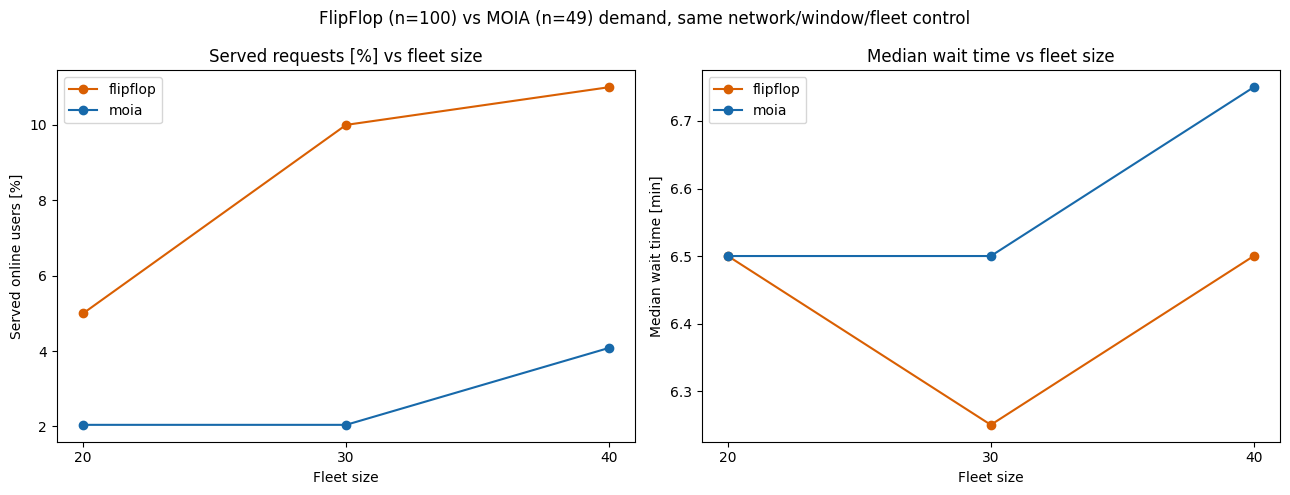

/Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/flipflop_drt_integration_pilot/results/flipflop_vs_moia_simulation_comparison.png


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {'flipflop': '#d95f02', 'moia': '#1769aa'}

for source in ['flipflop', 'moia']:
    sub = comparison[comparison['source'] == source].sort_values('fleet_size')
    axes[0].plot(sub['fleet_size'], sub['served_online_pct'], marker='o', color=colors[source], label=source)
    axes[1].plot(sub['fleet_size'], sub['median_wait_min'], marker='o', color=colors[source], label=source)

axes[0].set_title('Served requests [%] vs fleet size')
axes[0].set_xlabel('Fleet size')
axes[0].set_ylabel('Served online users [%]')
axes[0].legend()
axes[0].set_xticks([20, 30, 40])

axes[1].set_title('Median wait time vs fleet size')
axes[1].set_xlabel('Fleet size')
axes[1].set_ylabel('Median wait time [min]')
axes[1].legend()
axes[1].set_xticks([20, 30, 40])

fig.suptitle('FlipFlop (n=100) vs MOIA (n=49) demand, same network/window/fleet control')
fig.tight_layout()
output_path = RESULTS_DIR / 'flipflop_vs_moia_simulation_comparison.png'
fig.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()
print(output_path)

## Interpretation

- Absolute served counts are small for both sources (MOIA tops out at 2 of 50 served; FlipFlop at 11 of 100), so percentage swings between fleet sizes are noisy single-digit-count effects, not statistically robust trends.
- MOIA's served share (2-4%) is comparable to or lower than FlipFlop's (5-11%) at the same fleet sizes, despite MOIA being real observed demand rather than a synthetic sample — the low service rate is not an artifact of using FlipFlop data specifically.
- Shared rides only appear in the FlipFlop scenarios (36-40% at fleet 30/40) and never in MOIA (0% throughout) - consistent with MOIA's much smaller retained sample (49 requests) rarely producing spatially/temporally poolable pairs.
- This reinforces the study's recurring finding: at pilot scale (a few dozen vehicles, whole-city area, a 2-hour window), spatial coverage is the binding constraint, not which demand source is used.
- Next: repeat this comparison for more FlipFlop draws (2-5) to see whether draw-to-draw variance changes this picture, and consider a longer time window or larger candidate pool to get more than a handful of served requests per run.